<a href="https://colab.research.google.com/github/wilmaayuni1-del/middle-income-trap-ml/blob/main/Middle_Income_Trap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting the Middle-Income Trap
### Which middle-income countries will become high-income within 10 years?
**Final Project** | Data: World Bank (World Development Indicators + income classifications)

### Roadmap

| Assignment item | Section |
|---|---|
| 1-2. Background and objectives | Section 0 |
| 3. Dataset | Sections 1-2 |
| 4. Exploratory Data Analysis (EDA) | Section 3 |
| 5-6. Models and model comparison (3+ models) | Sections 4-5 |
| 8. Evaluation results | Sections 5-6 |
| 7. Prediction / forecast | Section 8 |
| 9. Summary (best model, why, challenges) | Sections 7 and 9 |


## Quick glossary

| Term | Simple meaning |
|---|---|
| **Classification** | Predicting a *category* (here: "moves up to high income" = 1 or "does not" = 0), not a number |
| **Supervised learning** | Teaching a model with examples where the right answer is already known |
| **Feature** | An input variable, e.g. internet users, investment, inflation |
| **Target / label** | The answer we want to predict (moves up to high income within 10 years: yes/no) |
| **Train / test split** | Learn from one part of the data, then check the model on a part it has never seen |
| **Overfitting** | The model memorises the training data and fails on new data |
| **Class imbalance** | One answer is much rarer than the other (moving up to high income is rare) |
| **PR-AUC** | A score (0 to 1) of how well the model finds the rare "yes" cases without too many false alarms |
| **ROC-AUC** | A score (0.5 = coin flip, 1 = perfect) of how well the model ranks "yes" above "no" |
| **SHAP** | A method that shows how much each feature pushed a prediction up or down |

## 0. Background and objectives

*middle-income trap* describes countries that grow quickly up to a middle income level, then get stuck and fail to reach high-income status. The World Bank groups countries into **low, lower-middle, upper-middle and high income** using GNI per capita (Atlas method). This matters for Indonesia, which aims to become a high-income country by 2045 ("Indonesia Emas 2045").

**Research question.** Which factors most strongly determine whether a middle-income country reaches high-income status within 10 years, and how accurately can machine learning predict it?

**Objectives**
1. Build a country-by-year dataset from World Bank indicators.
2. Compare at least 3 classification models using a *time-based* validation.
3. Identify the key drivers with permutation importance and SHAP.
4. Predict the probability of moving up to high income for middle-income countries, especially Indonesia and ASEAN.

**Target definition.** For a middle-income country *i* in year *t*:
`target = 1` if the country is **high income in any year from t+1 to t+10**, otherwise `0`.

## 1. Setup and configuration

> We install two helper libraries and load the tools we need.

In [1]:
!pip install -q wbgapi shap

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wbgapi as wb

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

# ---------------- SETTINGS (you can change these) ----------------
SEED        = 42            # makes results reproducible
HORIZON     = 10            # predict a move to high income within N years
START_YEAR  = 1990          # World Bank indicators are mostly complete from ~1990
END_YEAR    = 2025
SAMPLE      = 'all_middle'  # 'all_middle' (lower + upper middle) or 'upper_middle' only
TRAIN_END   = 2005          # last starting year t used for training; later years are the test set
BASE_YEAR   = 2023          # year whose data is used for the forward-looking forecast
MAX_MISSING = 0.40          # drop features with more than 40% missing values
# ------------------------------------------------------------------

# World Bank indicator code -> short column name
INDICATORS = {
    'NY.GNP.PCAP.CD':       'gni_pc',            # GNI per capita, Atlas method (US$)
    'NY.GDP.PCAP.KD.ZG':    'gdp_pc_growth',     # GDP per capita growth (%)
    'NE.GDI.TOTL.ZS':       'investment',        # gross capital formation (% of GDP)
    'NE.TRD.GNFS.ZS':       'trade',             # trade (% of GDP)
    'BX.KLT.DINV.WD.GD.ZS': 'fdi',               # foreign direct investment, net inflows (% of GDP)
    'NV.IND.MANF.ZS':       'manufacturing',     # manufacturing value added (% of GDP)
    'NV.AGR.TOTL.ZS':       'agriculture',       # agriculture value added (% of GDP)
    'TX.VAL.TECH.MF.ZS':    'high_tech_exports', # high-tech exports (% of manufactured exports)
    'IT.NET.USER.ZS':       'internet_users',    # internet users (% of population)
    'SE.SEC.ENRR':          'secondary_enroll',  # secondary school enrolment, gross (%)
    'SE.XPD.TOTL.GD.ZS':    'edu_spending',      # education spending (% of GDP)
    'GB.XPD.RSDV.GD.ZS':    'rnd_spending',      # R&D spending (% of GDP)
    'SP.POP.1564.TO.ZS':    'working_age_share', # population aged 15-64 (% of total)
    'SP.URB.TOTL.IN.ZS':    'urbanization',      # urban population (% of total)
    'SP.DYN.LE00.IN':       'life_expectancy',   # life expectancy (years)
    'FP.CPI.TOTL.ZG':       'inflation',         # inflation, consumer prices (%)
    'SP.POP.TOTL':          'population',        # total population
}

## 2. Dataset
### 2a. Income-group labels (World Bank, 1987-2025)

> For every country and year, which income group the World Bank put it in. We convert the group names into numbers: 1 = low, 2 = lower-middle, 3 = upper-middle, 4 = high. Later we use it to build our "did the country move up to high income?" answer.
>
> *Source:* the CSV below comes from Our World in Data, which republishes the World Bank classification.

In [3]:
INCOME_URL = ("https://ourworldindata.org/grapher/world-bank-income-groups.csv"
              "?v=1&csvType=full&useColumnShortNames=false")
raw = pd.read_csv(INCOME_URL, storage_options={'User-Agent': 'Mozilla/5.0'})
print(raw.shape)
display(raw.head())

cls_col = [c for c in raw.columns if c not in ('Entity', 'Code', 'Year')][0]

def to_level(s):
    # convert income-group text into a number 1-4
    s = str(s).lower()
    if 'lower' in s: return 2
    if 'upper' in s: return 3
    if 'high'  in s: return 4
    if 'low'   in s: return 1
    return np.nan          # unclassified

inc = raw.rename(columns={'Entity': 'country', 'Code': 'iso3', 'Year': 'year'})
inc['income_level'] = inc[cls_col].map(to_level)
inc = inc.dropna(subset=['iso3', 'income_level'])
inc = inc[(inc['iso3'].str.len() == 3) & ~inc['iso3'].str.startswith('OWID')]  # keep real countries
print('Classified countries:', inc['iso3'].nunique(), '| years:', inc['year'].min(), '-', inc['year'].max())
inc['income_level'].value_counts().sort_index()

(8173, 4)


,Entity,Code,Year,World Bank's income classification
0,Afghanistan,AFG,1987,Low-income countries
1,Afghanistan,AFG,1988,Low-income countries
2,Afghanistan,AFG,1989,Low-income countries
3,Afghanistan,AFG,1990,Low-income countries
4,Afghanistan,AFG,1991,Low-income countries


Classified countries: 220 | years: 1987 - 2025


,count
income_level,
1,1780
2,2116
3,1705
4,2493


### 2b. Economic indicators from the World Bank API

> For each indicator in our list, we ask the World Bank website for all countries and all years.

In [4]:
frames = []
for code_, name in INDICATORS.items():
    try:
        d = wb.data.DataFrame(code_, economy='all', time=range(START_YEAR, END_YEAR + 1),
                              labels=False, numericTimeKeys=True)
        d.columns = [int(str(c).replace('YR', '')) for c in d.columns]
        s = d.stack()
        s.index.names = ['iso3', 'year']
        s.name = name
        frames.append(s)
        print(f'OK   {code_:<24} {name:<20} {s.notna().sum():>6} observations')
    except Exception as e:
        print(f'SKIP {code_:<24} {name:<20} {type(e).__name__}: {e}')

wdi = pd.concat(frames, axis=1).reset_index()
print(wdi.shape)

OK   NY.GNP.PCAP.CD           gni_pc                 8642 observations
OK   NY.GDP.PCAP.KD.ZG        gdp_pc_growth          9023 observations
OK   NE.GDI.TOTL.ZS           investment             7372 observations
OK   NE.TRD.GNFS.ZS           trade                  7564 observations
OK   BX.KLT.DINV.WD.GD.ZS     fdi                    8480 observations
OK   NV.IND.MANF.ZS           manufacturing          7667 observations
OK   NV.AGR.TOTL.ZS           agriculture            8254 observations
OK   TX.VAL.TECH.MF.ZS        high_tech_exports      3360 observations
OK   IT.NET.USER.ZS           internet_users         6896 observations
OK   SE.SEC.ENRR              secondary_enroll       5842 observations
OK   SE.XPD.TOTL.GD.ZS        edu_spending           5173 observations
OK   GB.XPD.RSDV.GD.ZS        rnd_spending           3199 observations
OK   SP.POP.1564.TO.ZS        working_age_share      9540 observations
OK   SP.URB.TOTL.IN.ZS        urbanization           9540 observations
OK   S

### 2c. Build the panel, features and target

> We now stitch everything into one table where **each row = one country in one year**.
> 1. **Fill small gaps:** if a value is missing, we carry the last known value forward (max 3 years). This only uses the *past*, so the model never "peeks" at the future.
> 2. **Create helpful features:** `log_gni_pc` (income on a log scale, because income is very skewed), `log_population`, and `gni_growth_5y` (how fast income grew over 5 years).
> 3. **Create the answer (target):** for each country-year we look at the next 10 years. If the country reaches high income in any of them, target = 1, else 0.

In [5]:
countries = inc[['iso3', 'country']].drop_duplicates('iso3')
years = range(START_YEAR, END_YEAR + 1)
grid = pd.MultiIndex.from_product([countries['iso3'], years], names=['iso3', 'year']).to_frame(index=False)

panel = (grid.merge(countries, on='iso3')
             .merge(inc[['iso3', 'year', 'income_level']], on=['iso3', 'year'], how='left')
             .merge(wdi, on=['iso3', 'year'], how='left')
             .sort_values(['iso3', 'year']).reset_index(drop=True))

# 1) fill short gaps using past values only (no future information)
ind_cols = [c for c in INDICATORS.values() if c in panel.columns]
panel[ind_cols] = panel.groupby('iso3')[ind_cols].ffill(limit=3)

# 2) derived features
panel['log_gni_pc']     = np.log(panel['gni_pc'].where(panel['gni_pc'] > 0))
panel['log_population'] = np.log(panel['population'].where(panel['population'] > 0))
panel['gni_growth_5y']  = panel['gni_pc'] / panel.groupby('iso3')['gni_pc'].shift(5) - 1

# 3) target: high income (level 4) in any of the years t+1 ... t+HORIZON
lvl = panel.pivot(index='year', columns='iso3', values='income_level')   # rows = years, columns = countries
future = np.stack([lvl.shift(-k).values for k in range(1, HORIZON + 1)])  # income level k years ahead
future_max = pd.DataFrame(np.nanmax(future, axis=0), index=lvl.index, columns=lvl.columns)
tgt = (future_max == 4).astype(float).where(future_max.notna())
last_label_year = int(inc['year'].max()) - HORIZON
tgt.loc[tgt.index > last_label_year] = np.nan      # we cannot know the outcome of the last 10 years yet
print('Last year with a known outcome:', last_label_year)

tgt_long = tgt.rename_axis(index='year', columns='iso3').reset_index().melt(
    id_vars='year', var_name='iso3', value_name='target')
panel = panel.merge(tgt_long, on=['year', 'iso3'], how='left')

# 4) study population: middle-income countries in year t
levels = [3] if SAMPLE == 'upper_middle' else [2, 3]
sample = panel[panel['income_level'].isin(levels)].copy()
labeled = sample.dropna(subset=['target', 'log_gni_pc']).copy()
labeled['target'] = labeled['target'].astype(int)

# feature selection: drop features with too many missing values
CANDIDATES = ['log_gni_pc', 'gni_growth_5y', 'income_level', 'log_population'] + \
             [c for c in ind_cols if c not in ('gni_pc', 'population')]
miss = labeled[CANDIDATES].isna().mean().sort_values(ascending=False)
KEEP_ALWAYS = ['log_gni_pc', 'income_level']
FEATURES = [f for f in CANDIDATES if miss[f] <= MAX_MISSING or f in KEEP_ALWAYS]
print('Dropped (too many missing values):', [f for f in CANDIDATES if f not in FEATURES])
print('Features used:', FEATURES)
print(f'Labelled rows: {len(labeled)} | countries: {labeled.iso3.nunique()} | '
      f'years: {labeled.year.min()}-{labeled.year.max()}')
labeled.head()

Last year with a known outcome: 2015
Dropped (too many missing values): ['high_tech_exports', 'rnd_spending']
Features used: ['log_gni_pc', 'gni_growth_5y', 'income_level', 'log_population', 'gdp_pc_growth', 'investment', 'trade', 'fdi', 'manufacturing', 'agriculture', 'internet_users', 'secondary_enroll', 'edu_spending', 'working_age_share', 'urbanization', 'life_expectancy', 'inflation']
Labelled rows: 2399 | countries: 137 | years: 1990-2015


,iso3,year,country,income_level,gni_pc,gdp_pc_growth,investment,trade,fdi,manufacturing,agriculture,high_tech_exports,internet_users,secondary_enroll,edu_spending,rnd_spending,working_age_share,urbanization,life_expectancy,inflation,population,log_gni_pc,log_population,gni_growth_5y,target
1,ABW,1991,Aruba,3.0,12940.0,2.813435,NaN,NaN,21.185138,NaN,NaN,NaN,0.0,NaN,NaN,NaN,66.561472,65.400922,72.592,5.555556,65896.0,9.468079,11.095833,NaN,1
2,ABW,1992,Aruba,3.0,13840.0,1.111856,NaN,NaN,-3.857809,NaN,NaN,NaN,0.0,NaN,NaN,NaN,66.209790,65.390589,72.717,3.873375,69005.0,9.535318,11.141934,NaN,1
3,ABW,1993,Aruba,3.0,14380.0,0.492195,NaN,NaN,-1.655493,NaN,NaN,NaN,0.0,NaN,NaN,NaN,66.479531,65.384467,72.777,5.215560,73685.0,9.573594,11.207555,NaN,1
72,AGO,1990,Angola,2.0,790.0,-6.670527,0.0,NaN,-2.981429,NaN,NaN,NaN,0.0,9.64207,NaN,NaN,52.560511,37.878002,41.854,NaN,11626360.0,6.672033,16.268785,NaN,0
73,AGO,1991,Angola,2.0,920.0,-2.344653,0.0,NaN,6.266631,NaN,NaN,NaN,0.0,10.17320,NaN,NaN,52.353346,39.216271,43.812,83.783784,12023529.0,6.824374,16.302376,NaN,0


## 3. Exploratory Data Analysis (EDA)

> Before modelling, we *look* at the data. We want to know: how rare is an upgrade to high income, which variables are missing, how do the variables relate to each other, and how did real countries move over time.

### 3.1 How rare is an upgrade to high income? (class imbalance)

                    count   mean     std    min    25%    50%     75%      max
log_gni_pc         2399.0   8.03    0.80   3.69   7.41   8.07    8.63    10.05
gni_growth_5y      1913.0   0.53    0.96  -0.98   0.15   0.35    0.71    21.25
income_level       2399.0   2.42    0.49   2.00   2.00   2.00    3.00     3.00
log_population     2399.0  15.21    2.29   9.26  13.74  15.48   16.89    21.05
gdp_pc_growth      2399.0   2.42    6.84 -64.42   0.06   2.72    5.10   140.49
investment         1944.0  24.50    9.23 -12.88  18.84  23.34   29.09    76.78
trade              2029.0  81.95   37.34   0.00  54.09  78.97  102.46   268.36
fdi                2317.0   4.11    5.33 -19.77   1.03   2.74    5.73    74.12
manufacturing      2096.0  13.22    7.71   0.00   7.23  13.10   17.95    44.98
agriculture        2241.0  10.62    7.67   0.00   5.07   8.75   13.94    64.67
internet_users     2292.0  13.83   17.08   0.00   0.35   6.03   22.50    77.00
secondary_enroll   1872.0  74.71   22.10   9.64  61.

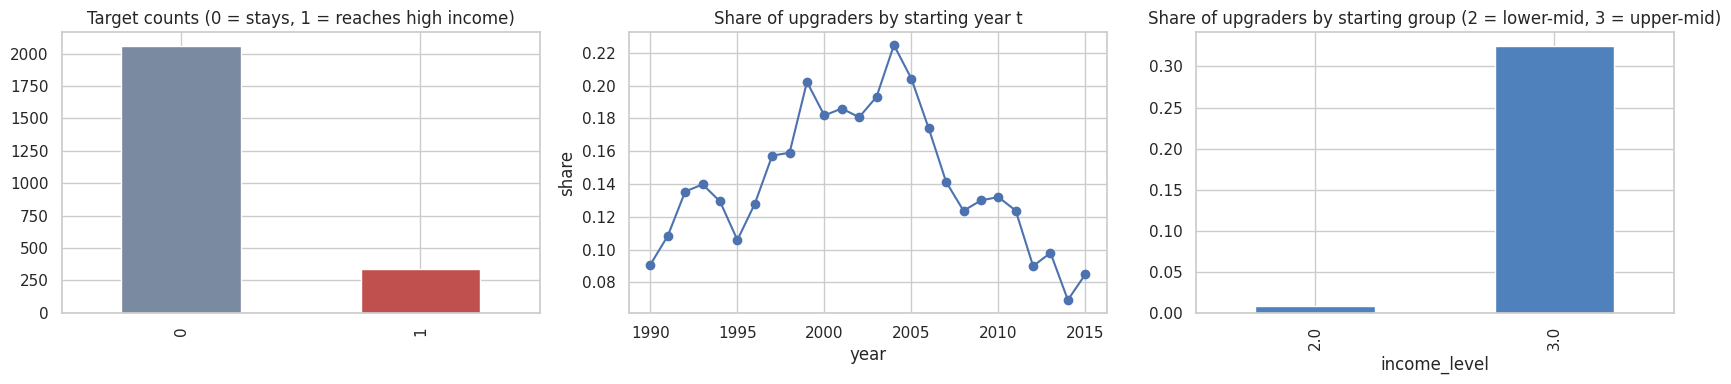

Share of positive cases: 0.141


In [6]:
print(labeled[FEATURES].describe().T.round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
labeled['target'].value_counts().sort_index().plot.bar(ax=ax[0], color=['#7a8aa0', '#c0504d'])
ax[0].set_title('Target counts (0 = stays, 1 = reaches high income)'); ax[0].set_xlabel('')

labeled.groupby('year')['target'].mean().plot(ax=ax[1], marker='o')
ax[1].set_title('Share of upgraders by starting year t'); ax[1].set_ylabel('share')

labeled.groupby('income_level')['target'].mean().plot.bar(ax=ax[2], color='#4f81bd')
ax[2].set_title('Share of upgraders by starting group (2 = lower-mid, 3 = upper-mid)')
plt.tight_layout(); plt.show()
print('Share of positive cases:', round(labeled['target'].mean(), 3))

> * if the red bar ("1") is much shorter than the grey bar ("0"), the data is **imbalanced**. A lazy model that always says "no upgrade" would look accurate but be useless. That is why we later use PR-AUC and class weights instead of plain accuracy.

### 3.2 Missing values and distributions

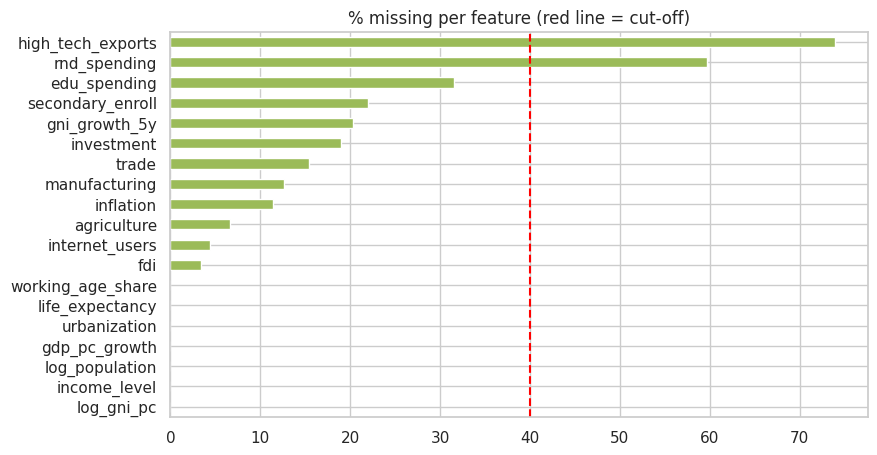

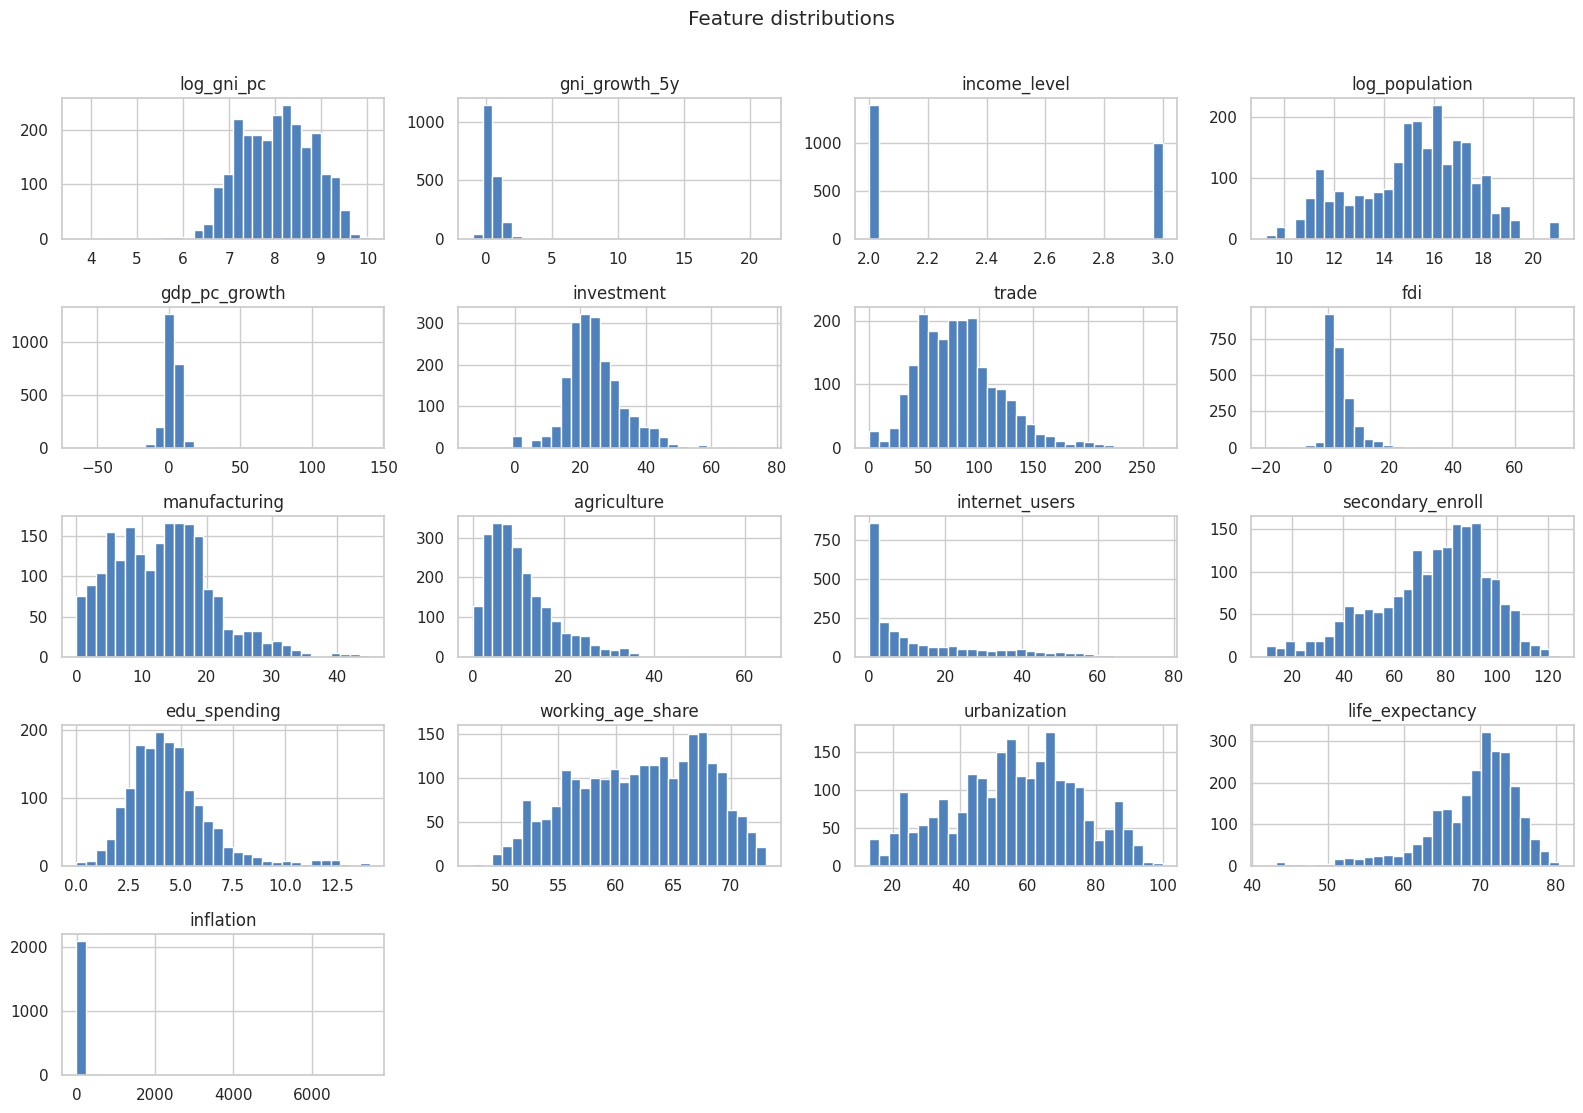

In [7]:
plt.figure(figsize=(9, 5))
(miss.sort_values() * 100).plot.barh(color='#9bbb59')
plt.axvline(MAX_MISSING * 100, color='red', ls='--')
plt.title('% missing per feature (red line = cut-off)'); plt.show()

labeled[FEATURES].hist(bins=30, figsize=(16, 11), color='#4f81bd')
plt.suptitle('Feature distributions', y=1.01); plt.tight_layout(); plt.show()

> Features right of the red line were dropped (too many gaps to trust). The histograms show the shape of each variable. Very skewed variables (like income and population) are the reason we used log versions.

### 3.3 Correlations and differences between upgraders and non-upgraders

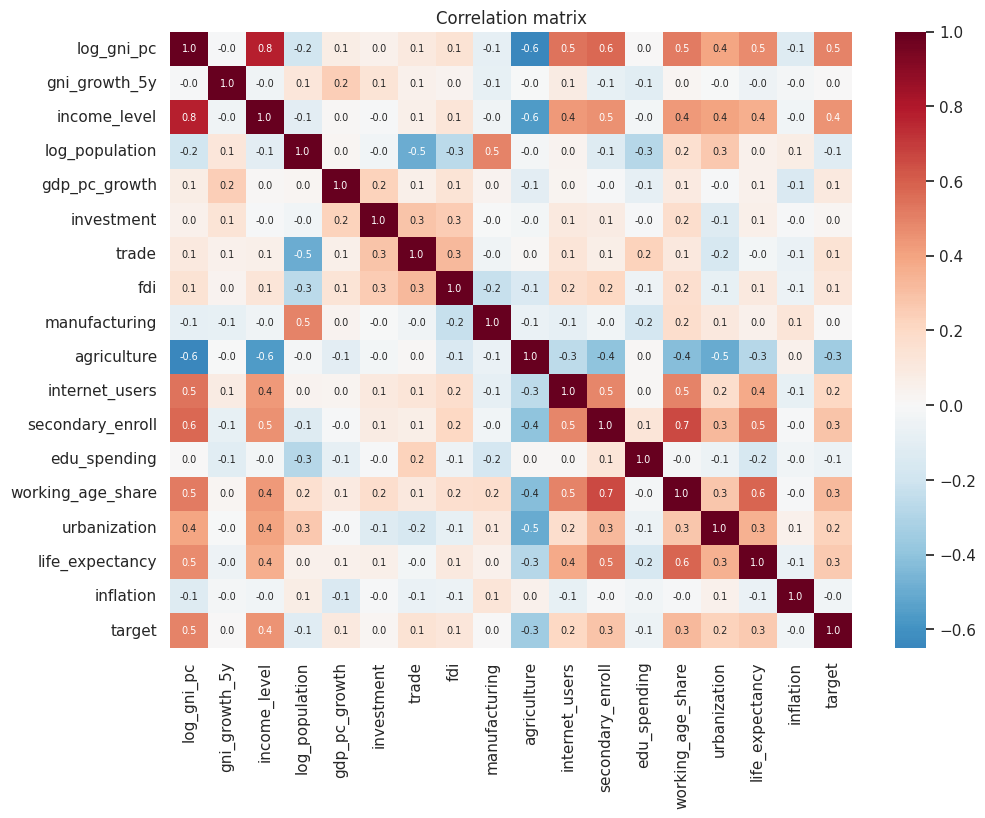

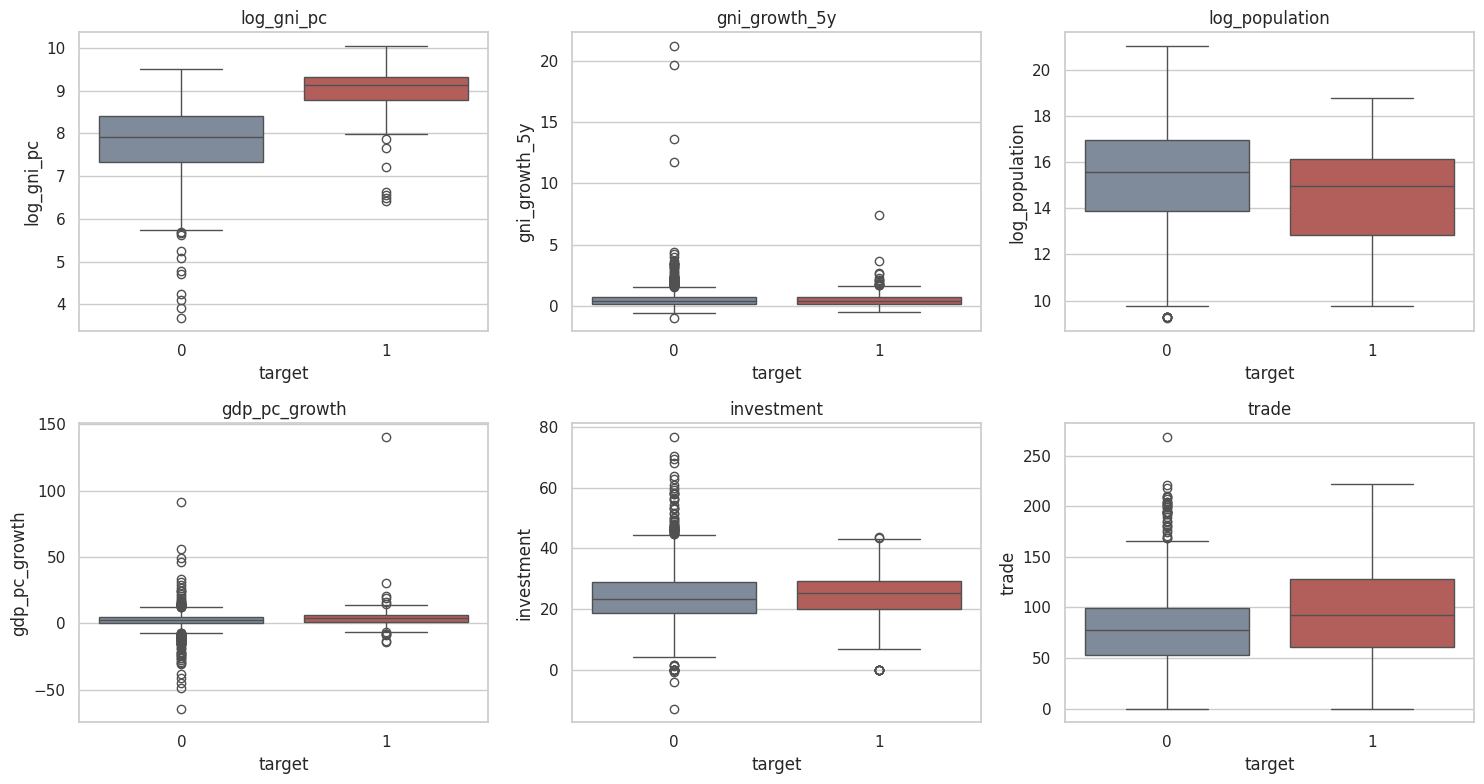

In [8]:
plt.figure(figsize=(11, 8))
sns.heatmap(labeled[FEATURES + ['target']].corr(), cmap='RdBu_r', center=0, annot=True, fmt='.1f',
            annot_kws={'size': 7})
plt.title('Correlation matrix'); plt.show()

top = ['log_gni_pc', 'gni_growth_5y'] + [f for f in FEATURES if f not in ('log_gni_pc', 'gni_growth_5y', 'income_level')][:4]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, f in zip(axes.ravel(), top):
    sns.boxplot(data=labeled, x='target', y=f, ax=a, palette=['#7a8aa0', '#c0504d'])
    a.set_title(f)
plt.tight_layout(); plt.show()

> In the heatmap, red = move together, blue = move in opposite directions. In the box plots, if the red box (upgraders) sits clearly higher or lower than the grey box, that feature separates the two groups well. **Correlation is not causation.**

### 3.4 Real country paths and the list of 'upgraders'

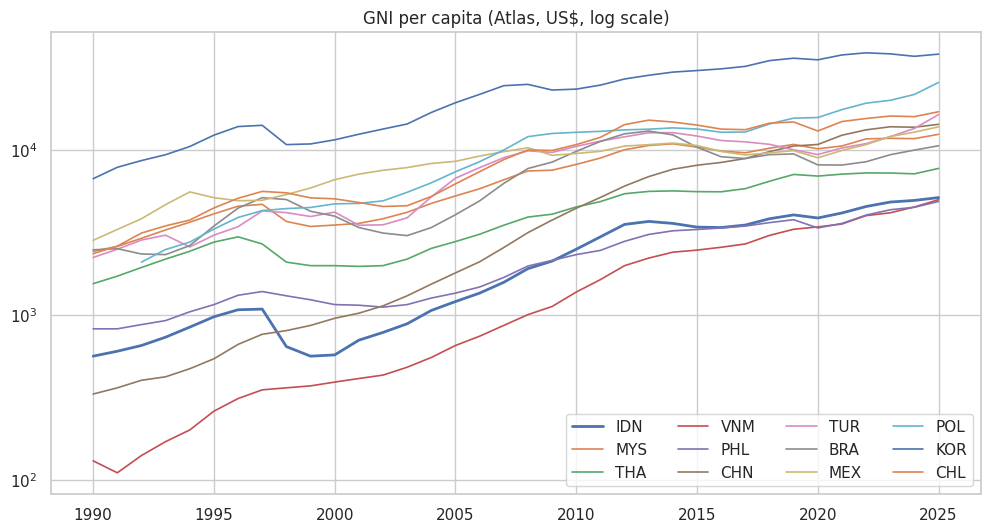

Countries that moved from middle to high income: 43


,iso3,first_middle_year,first_high_year,years_to_upgrade
0,ANT,1990,1994,4
23,MAC,1990,1994,4
33,PRT,1990,1994,4
20,KOR,1990,1995,5
25,MNP,1992,1995,3
27,NCL,1990,1995,5
14,GUM,1990,1995,5
13,GRC,1990,1996,6
38,SVN,1992,1997,5
24,MLT,1990,1998,8


In [9]:
focus = ['IDN', 'MYS', 'THA', 'VNM', 'PHL', 'CHN', 'TUR', 'BRA', 'MEX', 'POL', 'KOR', 'CHL']
fig, ax = plt.subplots(figsize=(12, 6))
for c in focus:
    d = panel[(panel.iso3 == c) & panel.gni_pc.notna()]
    if len(d): ax.plot(d.year, d.gni_pc, label=c, lw=2 if c == 'IDN' else 1.2)
ax.set_yscale('log'); ax.set_title('GNI per capita (Atlas, US$, log scale)')
ax.legend(ncol=4); plt.show()

# countries that were middle income at some point and later became high income
upgraders = []
for c in lvl.columns:
    s = lvl[c].dropna()
    mid = s[s.isin([2, 3])]
    if len(mid) and (s == 4).any():
        first_high = s[s == 4].index.min()
        if first_high > mid.index.min():
            upgraders.append((c, int(mid.index.min()), int(first_high)))
upgraders = pd.DataFrame(upgraders, columns=['iso3', 'first_middle_year', 'first_high_year'])
upgraders['years_to_upgrade'] = upgraders['first_high_year'] - upgraders['first_middle_year']
print('Countries that moved from middle to high income:', len(upgraders))
upgraders.sort_values('first_high_year')

> The line chart uses a log scale, so equal vertical distances mean equal *percentage* growth. The table lists real "success stories" and how long they took.

## 4. Train/test split and the models

> We split the data **by time**. The model learns from the past (starting years up to `TRAIN_END`) and is then tested on later years it has never seen.
>
> We then train **4 models** and compare them:
>
> | Model | Idea in one line |
> |---|---|
> | **Benchmark: Logistic Regression with GNI only** | The simplest rule: richer countries are more likely to move up. Do other features add anything beyond income? |
> | **Logistic Regression** | Draws a straight-line boundary between upgraders and non-upgraders and outputs a probability. Easy to interpret. |
> | **Random Forest** | Hundreds of decision trees vote together. Captures non-linear patterns and interactions. |
> | **XGBoost** | Trees built one after another, each fixing the mistakes of the previous ones. Often the most accurate on table-like data. |


In [10]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from scipy.stats import loguniform, randint, uniform

train = labeled[labeled.year <= TRAIN_END]
test  = labeled[labeled.year >  TRAIN_END]
ytr, yte = train['target'], test['target']
print(f'Train: {len(train)} rows | positives {ytr.mean():.1%} | starting years <= {TRAIN_END}')
print(f'Test : {len(test)} rows | positives {yte.mean():.1%} | starting years >  {TRAIN_END}')
assert yte.sum() > 0 and ytr.sum() > 0, 'Change TRAIN_END: one split has no positive cases'

# missing values are filled with the median of the training data (inside each pipeline)
imp = lambda: SimpleImputer(strategy='median', keep_empty_features=True)
spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)   # ratio of negatives to positives

specs = {
    'Benchmark: GNI-only Logit': dict(
        feats=['log_gni_pc', 'income_level'],
        est=Pipeline([('imp', imp()), ('sc', StandardScaler()),
                      ('clf', LogisticRegression(class_weight='balanced', max_iter=2000))]),
        params=None),
    'Logistic Regression': dict(
        feats=FEATURES,
        est=Pipeline([('imp', imp()), ('sc', StandardScaler()),
                      ('clf', LogisticRegression(class_weight='balanced', max_iter=5000))]),
        params={'clf__C': loguniform(1e-3, 1e2)}),
    'Random Forest': dict(
        feats=FEATURES,
        est=Pipeline([('imp', imp()),
                      ('clf', RandomForestClassifier(class_weight='balanced_subsample',
                                                     random_state=SEED, n_jobs=-1))]),
        params={'clf__n_estimators': randint(200, 600), 'clf__max_depth': randint(3, 14),
                'clf__min_samples_leaf': randint(1, 15), 'clf__max_features': uniform(0.3, 0.6)}),
    'XGBoost': dict(
        feats=FEATURES,
        est=Pipeline([('imp', imp()),
                      ('clf', XGBClassifier(eval_metric='logloss', scale_pos_weight=spw,
                                            random_state=SEED, n_jobs=-1))]),
        params={'clf__n_estimators': randint(100, 500), 'clf__max_depth': randint(2, 7),
                'clf__learning_rate': loguniform(0.01, 0.3), 'clf__subsample': uniform(0.6, 0.4),
                'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__min_child_weight': randint(1, 8),
                'clf__reg_lambda': loguniform(0.1, 20)}),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, cv_score = {}, {}
for name, sp in specs.items():
    Xtr = train[sp['feats']]
    if sp['params'] is None:
        model = sp['est'].fit(Xtr, ytr)
        cv_score[name] = np.nan
    else:
        search = RandomizedSearchCV(sp['est'], sp['params'], n_iter=25, scoring='average_precision',
                                    cv=cv, random_state=SEED, n_jobs=-1, refit=True)
        search.fit(Xtr, ytr, groups=train['iso3'])
        model, cv_score[name] = search.best_estimator_, search.best_score_
        print(f'{name:<22} CV PR-AUC = {search.best_score_:.3f} | {search.best_params_}')
    fitted[name] = model

Train: 1398 rows | positives 15.9% | starting years <= 2005
Test : 1001 rows | positives 11.6% | starting years >  2005
Logistic Regression    CV PR-AUC = 0.791 | {'clf__C': np.float64(0.19069966103000435)}
Random Forest          CV PR-AUC = 0.852 | {'clf__max_depth': 11, 'clf__max_features': np.float64(0.3278702476319986), 'clf__min_samples_leaf': 3, 'clf__n_estimators': 334}
XGBoost                CV PR-AUC = 0.873 | {'clf__colsample_bytree': np.float64(0.6093821097865351), 'clf__learning_rate': np.float64(0.06673971219322068), 'clf__max_depth': 5, 'clf__min_child_weight': 1, 'clf__n_estimators': 417, 'clf__reg_lambda': np.float64(17.222639914460647), 'clf__subsample': np.float64(0.9849789179768444)}


## 5. Evaluation and model comparison (test set)

> Now we grade each model on the test years it has never seen. We report several scores because no single number tells the whole story:
>
> - **PR-AUC (main score):** how well the model finds true upgraders without too many false alarms. Compare it with the *baseline* printed below (the share of upgraders): a model must beat that to be useful.
> - **ROC-AUC:** how well the model ranks upgraders above non-upgraders. 0.5 = guessing, 1.0 = perfect.
> - **Precision:** of the countries the model *called* upgraders, how many really were?
> - **Recall:** of the countries that *really* moved up, how many did the model catch?
> - **F1:** one number that balances precision and recall.
> - **Brier score:** how close the predicted probabilities are to reality (**lower is better**).

Baseline PR-AUC for a random guesser = share of upgraders = 0.116


,ROC_AUC,PR_AUC,F1,Precision,Recall,Brier,CV_PR_AUC
Model,,,,,,,
XGBoost,0.921,0.697,0.470,0.316,0.914,0.185,0.873
Benchmark: GNI-only Logit,0.941,0.694,0.375,0.232,0.974,0.236,NaN
Logistic Regression,0.921,0.662,0.378,0.235,0.966,0.280,0.791
Random Forest,0.911,0.642,0.500,0.348,0.888,0.125,0.852


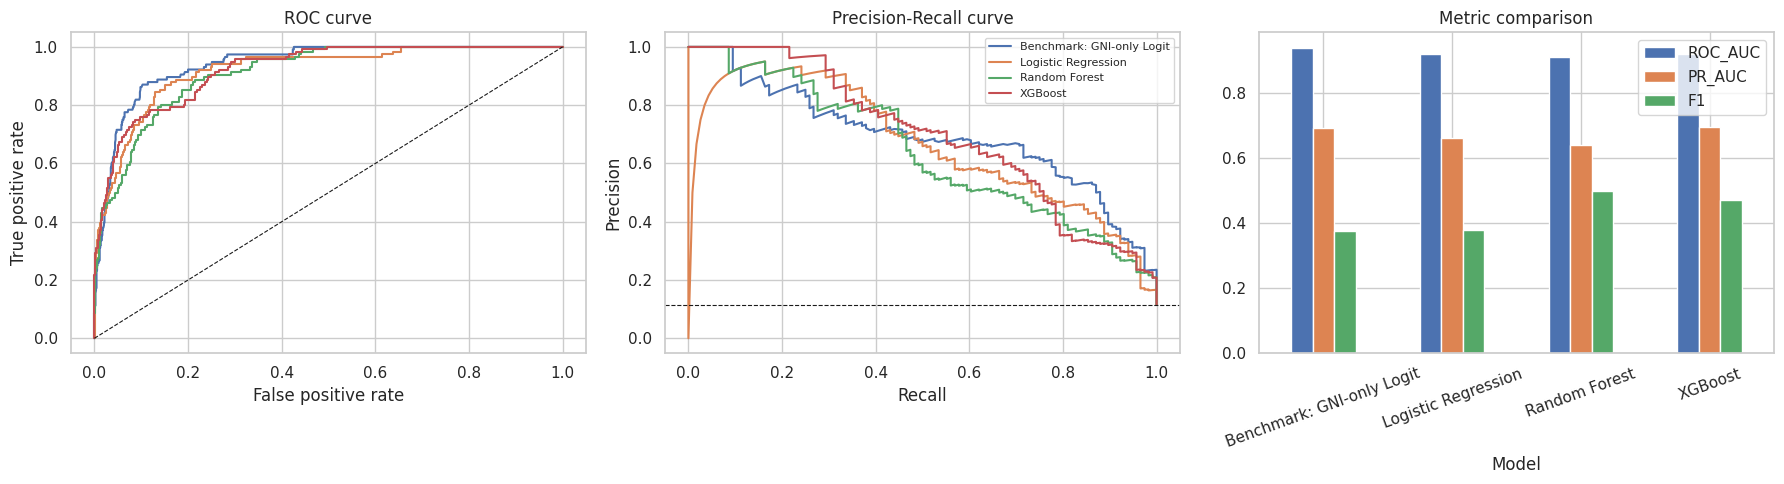

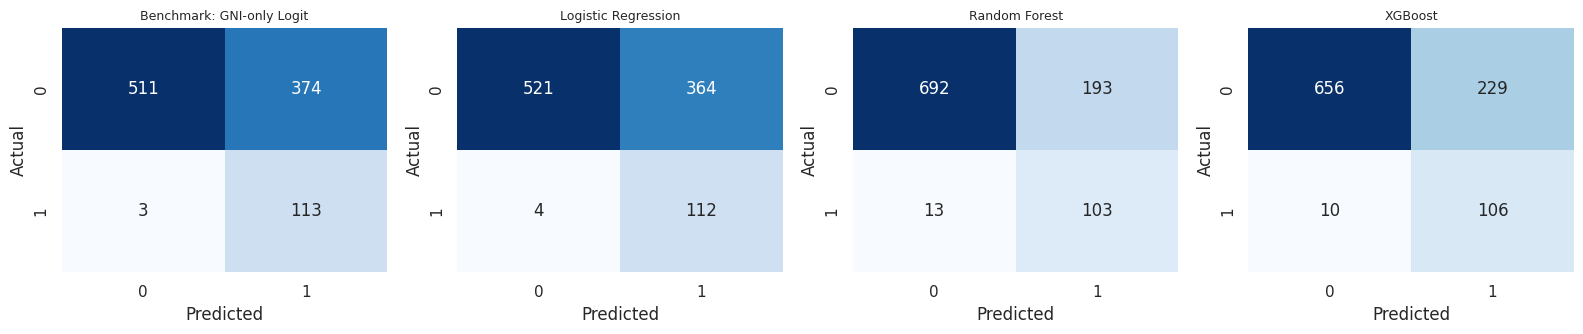

In [11]:
def evaluate(name, model, feats, X, y, thr=0.5):
    p = model.predict_proba(X[feats])[:, 1]       # predicted probability of moving up
    pred = (p >= thr).astype(int)                 # turn probability into yes/no at 50%
    return dict(Model=name, ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                F1=f1_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred), Brier=brier_score_loss(y, p), CV_PR_AUC=cv_score[name]), p

rows, probs = [], {}
for name, sp in specs.items():
    r, probs[name] = evaluate(name, fitted[name], sp['feats'], test, yte)
    rows.append(r)
results = pd.DataFrame(rows).set_index('Model').round(3)
print(f'Baseline PR-AUC for a random guesser = share of upgraders = {yte.mean():.3f}')
display(results.sort_values('PR_AUC', ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, label=name)
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('ROC curve'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[1].axhline(yte.mean(), color='k', ls='--', lw=.8); ax[1].set_title('Precision-Recall curve')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=8)
results[['ROC_AUC', 'PR_AUC', 'F1']].plot.bar(ax=ax[2]); ax[2].set_title('Metric comparison'); ax[2].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(probs), figsize=(4 * len(probs), 3.5))
for a, (name, p) in zip(axes, probs.items()):
    sns.heatmap(confusion_matrix(yte, (p >= .5).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a)
    a.set_title(name, fontsize=9); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

> Curves closer to the top-left (ROC) or top-right (Precision-Recall) are better. The dashed line is a random guesser. In each confusion matrix, the diagonal cells are correct predictions; the off-diagonal cells are mistakes (top-right = false alarms, bottom-left = missed upgraders).

## 6. Robustness check: does the winner stay the winner?

> One train/test split can be lucky for one model. So we repeat the experiment with several different cut-off years (train up to 1998, then 2001, 2004, ...) and test on the next 4 years each time. A model that wins *consistently* is more trustworthy than one that wins once.

In [12]:
cutoffs = [1998, 2001, 2004, 2007, 2010]
rows = []
for c in cutoffs:
    tr = labeled[labeled.year <= c]; te = labeled[(labeled.year > c) & (labeled.year <= c + 4)]
    if tr['target'].sum() == 0 or te['target'].sum() == 0 or te['target'].nunique() < 2:
        continue
    for name, sp in specs.items():
        m = clone(fitted[name]).fit(tr[sp['feats']], tr['target'])
        p = m.predict_proba(te[sp['feats']])[:, 1]
        rows.append(dict(cutoff=c, Model=name, PR_AUC=average_precision_score(te['target'], p),
                         ROC_AUC=roc_auc_score(te['target'], p), prevalence=te['target'].mean()))
roll = pd.DataFrame(rows)
display(roll.pivot(index='cutoff', columns='Model', values='PR_AUC').round(3))
print('Average across cut-offs:')
display(roll.groupby('Model')[['PR_AUC', 'ROC_AUC']].mean().round(3).sort_values('PR_AUC', ascending=False))

Model,Benchmark: GNI-only Logit,Logistic Regression,Random Forest,XGBoost
cutoff,,,,
1998,0.725,0.800,0.901,0.939
2001,0.766,0.775,0.876,0.878
2004,0.795,0.808,0.772,0.805
2007,0.835,0.713,0.832,0.899
2010,0.606,0.695,0.876,0.888


Average across cut-offs:


,PR_AUC,ROC_AUC
Model,,
XGBoost,0.882,0.960
Random Forest,0.852,0.954
Logistic Regression,0.758,0.929
Benchmark: GNI-only Logit,0.745,0.931


## 7. Interpretation: what drives the move to high income?

> A good model is not enough; we want to know **why** it predicts what it predicts.
>
> - **Best model:** chosen automatically from the 3 main models by the highest test PR-AUC. Always cross-check with Section 6.
> - **Permutation importance:** we shuffle one feature at a time. If the score drops a lot, that feature mattered.
> - **SHAP:** for each country-year, shows how much every feature pushed the prediction *up* (red = high feature value) or *down*. Dots on the right increase the chance of moving up.
>
> **Important** these show what the model *associates* with moving up, not what *causes* it.

Best model (highest test PR-AUC): XGBoost


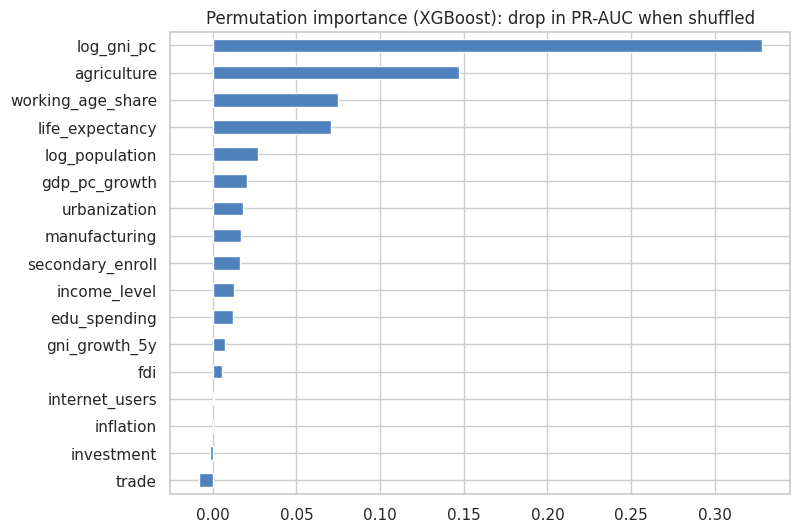

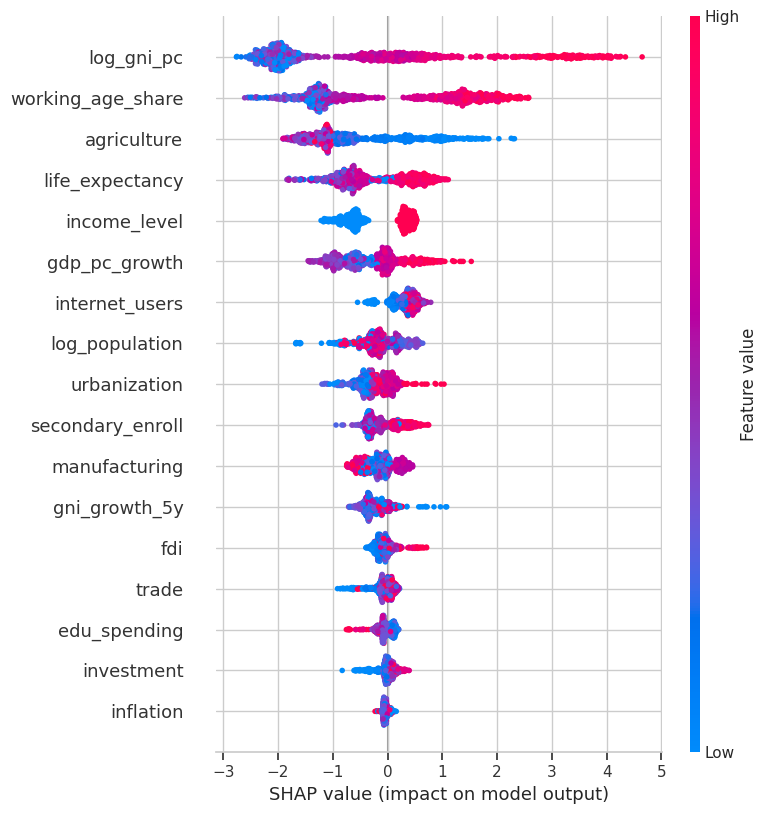

In [13]:
from sklearn.inspection import permutation_importance

main = ['Logistic Regression', 'Random Forest', 'XGBoost']
best_name = results.loc[main, 'PR_AUC'].idxmax()
print('Best model (highest test PR-AUC):', best_name)
best_feats = specs[best_name]['feats']

pi = permutation_importance(fitted[best_name], test[best_feats], yte, scoring='average_precision',
                            n_repeats=20, random_state=SEED, n_jobs=-1)
imp_df = pd.Series(pi.importances_mean, index=best_feats).sort_values()
imp_df.plot.barh(figsize=(8, 6), color='#4f81bd')
plt.title(f'Permutation importance ({best_name}): drop in PR-AUC when shuffled'); plt.show()

# SHAP for XGBoost (tree-based model)
try:
    import shap
    xgb_fit = fitted['XGBoost']
    Xte_t = pd.DataFrame(xgb_fit[:-1].transform(test[FEATURES]), columns=FEATURES)
    explainer = shap.TreeExplainer(xgb_fit.named_steps['clf'])
    sv = explainer.shap_values(Xte_t)
    shap.summary_plot(sv, Xte_t, show=True)
except Exception as e:
    print('SHAP skipped:', type(e).__name__, e)

## 8. Prediction / forecast

> We retrain the best model on **all** labelled data, then feed it the latest data (`BASE_YEAR`). The result is, for each middle-income country, the **probability of reaching high income within the next 10 years**. Treat these as *risk-style scores*, not certainties.

Probability of reaching high income within 10 years (data year 2023, model: XGBoost)


,iso3,country,income_level,gni_pc,prob_high_income,rank
0,CRI,Costa Rica,3.0,14330.0,0.987,1
1,MNE,Montenegro,3.0,11560.0,0.985,2
2,MUS,Mauritius,3.0,12530.0,0.983,3
3,LCA,Saint Lucia,3.0,12440.0,0.977,4
4,SRB,Serbia,3.0,10750.0,0.948,5
5,ARG,Argentina,3.0,12920.0,0.929,6
6,GRD,Grenada,3.0,10100.0,0.908,7
7,LBY,Libya,3.0,6160.0,0.828,8
8,KAZ,Kazakhstan,3.0,10710.0,0.821,9
9,MEX,Mexico,3.0,11990.0,0.729,10


ASEAN countries that are still middle income in the base year:


,iso3,country,income_level,gni_pc,prob_high_income,rank
13,MYS,Malaysia,3.0,11700.0,0.558,14
31,THA,Thailand,3.0,7210.0,0.035,32
35,IDN,Indonesia,3.0,4810.0,0.026,36
51,PHL,Philippines,2.0,4320.0,0.003,52
62,VNM,Vietnam,2.0,4140.0,0.001,63
64,KHM,Cambodia,2.0,2390.0,0.001,65
77,LAO,Laos,2.0,2110.0,0.001,78
83,MMR,Myanmar,2.0,1220.0,0.001,84


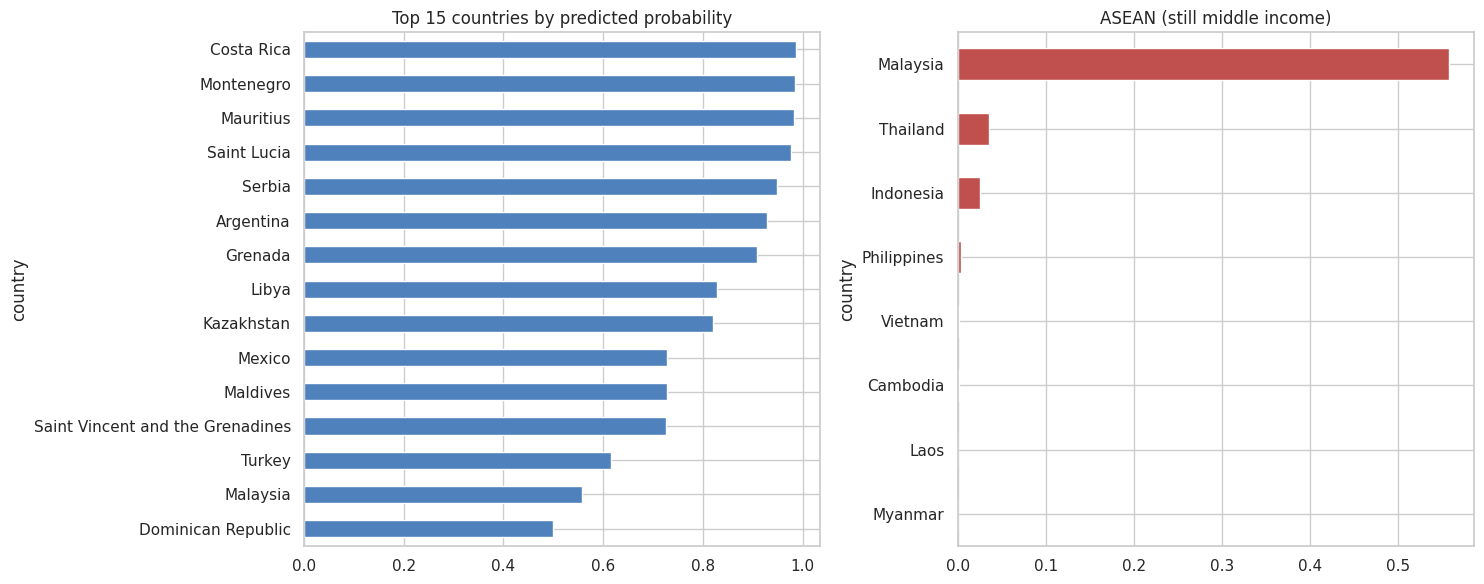

In [14]:
final = clone(fitted[best_name]).fit(labeled[best_feats], labeled['target'])

base = panel[(panel.year == BASE_YEAR) & panel['income_level'].isin(levels)].dropna(subset=['log_gni_pc']).copy()
base['prob_high_income'] = final.predict_proba(base[best_feats])[:, 1]
pred_tbl = (base[['iso3', 'country', 'income_level', 'gni_pc', 'prob_high_income']]
            .sort_values('prob_high_income', ascending=False).reset_index(drop=True))
pred_tbl['rank'] = pred_tbl.index + 1
print(f'Probability of reaching high income within {HORIZON} years (data year {BASE_YEAR}, model: {best_name})')
display(pred_tbl.head(20).round(3))

asean = ['IDN', 'MYS', 'THA', 'VNM', 'PHL', 'KHM', 'LAO', 'MMR']
a = pred_tbl[pred_tbl.iso3.isin(asean)]
print('ASEAN countries that are still middle income in the base year:')
display(a.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pred_tbl.head(15).iloc[::-1].plot.barh(x='country', y='prob_high_income', ax=ax[0], legend=False, color='#4f81bd')
ax[0].set_title('Top 15 countries by predicted probability')
if len(a):
    a.sort_values('prob_high_income').plot.barh(x='country', y='prob_high_income', ax=ax[1], legend=False, color='#c0504d')
ax[1].set_title('ASEAN (still middle income)'); plt.tight_layout(); plt.show()

## 9. Model

**Model formulas (short version)**

- **Logistic Regression:** $P(y=1\mid x)=\sigma(w^\top x+b)=\dfrac{1}{1+e^{-(w^\top x+b)}}$, trained by minimising $-\sum_i [\,y_i\log p_i+(1-y_i)\log(1-p_i)\,]+\dfrac{1}{2C}\lVert w\rVert_2^2$
  *In words: a weighted sum of the features is squashed into a probability between 0 and 1.*
- **Random Forest:** average of $B$ decision trees, $\hat p(x)=\frac1B\sum_{b=1}^{B}T_b(x)$; each split minimises Gini impurity $G=1-\sum_k p_k^2$
  *In words: many different trees vote, and averaging reduces overfitting.*
- **XGBoost:** additive boosting, $\hat y_i=\sum_{m=1}^{M}f_m(x_i)$, with objective $\mathcal{L}=\sum_i \ell(y_i,\hat y_i)+\sum_m\Omega(f_m)$, $\ \Omega(f)=\gamma T+\tfrac12\lambda\lVert w\rVert^2$
  *In words: each new tree corrects the errors of the previous trees, while a penalty keeps the trees simple.*

**Metrics**

$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\,P\,R}{P+R},\quad \text{PR-AUC}=\int_0^1 P(R)\,dR$

**Suggested post structure:** the problem (middle-income trap, Indonesia 2045) > the data (World Bank, country-by-year panel) > the method (3 models + a benchmark, time-based validation) > the results (metric table, SHAP chart) > the Indonesia/ASEAN forecast.

## 10. Save results

In [16]:
labeled.to_csv('panel_labeled.csv', index=False)
results.to_csv('model_results.csv')
pred_tbl.to_csv('forecast_probabilities.csv', index=False)
try:
    from google.colab import files
    for f in ['panel_labeled.csv', 'model_results.csv', 'forecast_probabilities.csv']:
        files.download(f)
except Exception:
    print('Saved in the current working folder.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>